In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

# 1. Load dataset bersih hasil notebook 01
df = pd.read_csv("../data/processed/salary_multimodal_clean.csv")
df["combined_text"] = df["combined_text"].fillna("")

text_col = "combined_text"
cat_cols = ["formatted_experience_level", "formatted_work_type"]
num_cols = ["remote_allowed", "company_size", "views", "applies"]

X = df[[text_col] + cat_cols + num_cols]
y = df["normalized_salary"]

# 2. Split data 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Data Train: {X_train.shape[0]:,} baris | Data Test: {X_test.shape[0]:,} baris")

# 3. Multimodal Preprocessor (Teks + Kategorikal + Numerik)
preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(max_features=3000, ngram_range=(1, 2), stop_words="english"), text_col),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols),
    ]
)

Data Train: 28,407 baris | Data Test: 7,102 baris


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

models = {
    "Ridge Regression (Baseline)": Ridge(alpha=1.0),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100, max_depth=25, n_jobs=-1, random_state=42
    ),
    "MLP Neural Network": MLPRegressor(
        hidden_layer_sizes=(64, 32), max_iter=15, early_stopping=True, random_state=42
    ),
}

results = []
trained_pipelines = {}

for name, reg in models.items():
    print(f"Sedang melatih {name}...")
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", TransformedTargetRegressor(
            regressor=reg, func=np.log1p, inverse_func=np.expm1
        ))
    ])
    
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results.append({"Model": name, "MAE (USD)": mae, "RMSE (USD)": rmse, "R2 Score": r2})
    trained_pipelines[name] = pipe

results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
print("\n=== HASIL EVALUASI MODEL MULTIMODAL ===")
print(results_df.to_string(index=False))

Sedang melatih Ridge Regression (Baseline)...
Sedang melatih Random Forest Regressor...
Sedang melatih MLP Neural Network...


c:\Users\LEGION\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(



=== HASIL EVALUASI MODEL MULTIMODAL ===
                      Model    MAE (USD)   RMSE (USD)  R2 Score
Ridge Regression (Baseline) 21907.457252 36518.075491  0.586649
    Random Forest Regressor 21959.350879 37220.469605  0.570595
         MLP Neural Network 22711.411315 51220.267931  0.186819


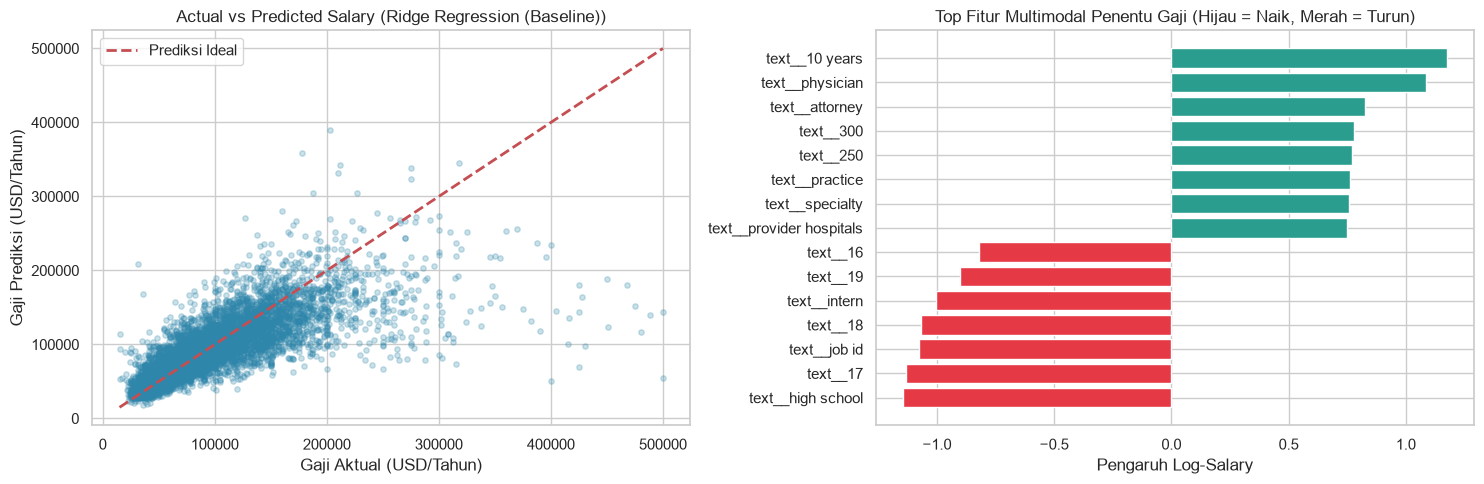

In [3]:
# Ambil model terbaik berdasarkan R2 tertinggi
best_model_name = results_df.iloc[0]["Model"]
best_pipe = trained_pipelines[best_model_name]
y_pred_best = best_pipe.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Actual vs Predicted Salary
axes[0].scatter(y_test, y_pred_best, alpha=0.25, color="#2E86AB", s=15)
axes[0].plot([15000, 500000], [15000, 500000], "r--", lw=2, label="Prediksi Ideal")
axes[0].set_title(f"Actual vs Predicted Salary ({best_model_name})")
axes[0].set_xlabel("Gaji Aktual (USD/Tahun)")
axes[0].set_ylabel("Gaji Prediksi (USD/Tahun)")
axes[0].legend()

# Plot 2: Top 15 Fitur Paling Berpengaruh (dari model Ridge untuk interpretasi arah +/-)
ridge_pipe = trained_pipelines["Ridge Regression (Baseline)"]
feature_names = ridge_pipe.named_steps["preprocessor"].get_feature_names_out()
coefs = ridge_pipe.named_steps["regressor"].regressor_.coef_

feat_df = pd.DataFrame({"Fitur": feature_names, "Koefisien": coefs})
top_pos = feat_df.sort_values("Koefisien", ascending=False).head(8)
top_neg = feat_df.sort_values("Koefisien", ascending=True).head(7)
top_feats = pd.concat([top_pos, top_neg]).sort_values("Koefisien")

colors = ["#E63946" if c < 0 else "#2A9D8F" for c in top_feats["Koefisien"]]
axes[1].barh(top_feats["Fitur"], top_feats["Koefisien"], color=colors)
axes[1].set_title("Top Fitur Multimodal Penentu Gaji (Hijau = Naik, Merah = Turun)")
axes[1].set_xlabel("Pengaruh Log-Salary")

plt.tight_layout()
plt.show()

In [5]:
import joblib
from pathlib import Path

model_path = Path("../models/salary_multimodal_pipeline.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)  # Otomatis buat folder models jika belum ada

joblib.dump(best_pipe, model_path)
print(f"Model terbaik ({best_model_name}) berhasil disimpan ke: {model_path.resolve()}")

# Simulasi 1x prediksi seperti pada aplikasi Streamlit nanti
sample_input = pd.DataFrame([{
    "combined_text": "senior machine learning engineer python pytorch aws data science software development",
    "formatted_experience_level": "Mid-Senior level",
    "formatted_work_type": "Full-time",
    "remote_allowed": 1,
    "company_size": 7,
    "views": 50,
    "applies": 10
}])

prediksi_usd = best_pipe.predict(sample_input)[0]
print(f"Simulasi Prediksi Gaji: ${prediksi_usd:,.2f} / tahun")

Model terbaik (Ridge Regression (Baseline)) berhasil disimpan ke: C:\Users\LEGION\fp-datmin\multimodal-salary-prediction\models\salary_multimodal_pipeline.joblib
Simulasi Prediksi Gaji: $192,892.92 / tahun
